In [1]:
!pip install jumanji torchrl ipympl tensordict opencv-python matplotlib torchvision pillow

In [2]:
import jumanji
from torchrl.envs.libs import JumanjiEnv
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import torch
from torch.distributions import Categorical, Distribution
# Tensordict modules
from tensordict.nn import set_composite_lp_aggregate, TensorDictModule, TensorDictSequential, TensorDictModuleBase
from tensordict.nn.distributions import NormalParamExtractor
from torch import multiprocessing

# Data collection
from torchrl.collectors import SyncDataCollector
from torchrl.data.replay_buffers import ReplayBuffer
from torchrl.data.replay_buffers.samplers import SamplerWithoutReplacement
from torchrl.data.replay_buffers.storages import LazyTensorStorage

# Env
from torchrl.envs import RewardSum, TransformedEnv,Compose,StepCounter,RenameTransform,DTypeCastTransform
from torchrl.envs.utils import check_env_specs

# Multi-agent network
from torchrl.modules import MultiAgentMLP, ProbabilisticActor, TanhNormal

# Loss
from torchrl.objectives import ClipPPOLoss, ValueEstimators

# Utils
torch.manual_seed(0)
from matplotlib import pyplot as plt
from tqdm import tqdm

In [3]:
# HYPERPARAMETERS


# Seeds
ENV_SEED = 1234
TORCH_NUMPY_SEED = 0
device = "cpu"

# Environment parameters
BATCH_SIZE = 128
MAX_STEPS = 500
n_agents = 2

# Training parameters
frames_per_batch = 50_000  # Number of team frames collected per training iteration
n_iters = 20  # Number of sampling and training iterations
total_frames = frames_per_batch * n_iters

# Training
num_epochs = 5  # Number of optimization steps per training iteration
minibatch_size = 4_096  # Size of the mini-batches in each optimization step
lr = 3e-4  # Learning rate
max_grad_norm = 1.0  # Maximum norm for the gradients

# PPO
clip_epsilon = 0.2  # clip value for PPO loss
gamma = 0.99  # discount factor
lmbda = 0.95  # lambda for generalised advantage estimation
entropy_eps = 0.02  # coefficient of the entropy term in the PPO loss
# disable log-prob aggregation
#set_composite_lp_aggregate(False).set()

# Additional parameters
VOCAB_SIZE = 4

In [4]:
def set_seeds(seed=TORCH_NUMPY_SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)

In [5]:
env = JumanjiEnv("LevelBasedForaging-v0",
                 batch_size=[BATCH_SIZE]
                 )
env.set_seed(ENV_SEED)
env = TransformedEnv(
    env,
    Compose(
        StepCounter(max_steps=MAX_STEPS),
        RenameTransform(in_keys=["agents_view"], out_keys=["observation"]),
        DTypeCastTransform(
            dtype_in=torch.int32,
            dtype_out=torch.float32,
            in_keys=["observation"]
        ),
    )
)

/usr/local/lib/python3.12/dist-packages/torchrl/envs/libs/jumanji.py:70: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:206.)
  torch.as_tensor(np.asarray(spec.num_values)), dtype=dtype, device=device


In [6]:
def jumanji_env_render_callback(env, tensordict):
    image = env.render(tensordict)          # shape (3,H,W), torch tensor
    img = image.numpy().transpose(1, 2, 0)  # HWC

    if img.dtype != np.uint8:
        img = (img * 255).astype(np.uint8)

    cv2_imshow(img)
    cv2.waitKey(1)

### Render a random rollout

In [7]:

# tds = env.rollout(
#     max_steps=100,
#     callback=jumanji_env_render_callback
# )
# jumanji_env_render_callback(env, tds[-1]["next"])
# cv2.destroyAllWindows()


In [8]:
# print("action_spec:", env.full_action_spec)
# print("reward_spec:", env.full_reward_spec)
# print("done_spec:", env.full_done_spec)
# print("observation_spec:", env.observation_spec)

In [9]:
# print("action_keys:", env.action_keys)
# print("reward_keys:", env.reward_keys)
# print("done_keys:", env.done_keys)

In [10]:
n_agent_inputs = env.observation_spec["observation"].shape[-1] + VOCAB_SIZE

class ActionMessageNet(torch.nn.Module):
    def __init__(self, n_agent_inputs, vocab_size, n_agents, device="cpu"):
        super().__init__()

        self.torso = MultiAgentMLP(
            n_agent_inputs=n_agent_inputs,
            n_agent_outputs=256,
            n_agents=n_agents,
            centralised=False,
            share_params=True,
            device=device,
            depth=2,
            num_cells=256,
            activation_class=torch.nn.Tanh
        )

        self.action_head = torch.nn.Linear(256, 6)
        self.message_head = torch.nn.Linear(256, vocab_size)

    def forward(self, observation_communication):
        h = self.torso(observation_communication)

        logits = self.action_head(h)

        message_logits = self.message_head(h)

        return logits, message_logits


policy_heads_module = TensorDictModule(
    module=ActionMessageNet(
        n_agent_inputs=n_agent_inputs,
        vocab_size=VOCAB_SIZE,
        n_agents=n_agents,
        device=device
    ),
    in_keys=["observation_communication"],
    out_keys=["logits", "message_logits"]
)

In [11]:
action_actor = ProbabilisticActor(
    module=policy_heads_module,
    spec=env.action_spec_unbatched,
    in_keys=["logits"],
    out_keys=[env.action_key],
    distribution_class=Categorical,
    distribution_kwargs={
    },
    return_log_prob=True,
)

In [12]:
class MessageSampler(torch.nn.Module):
    def __init__(self, force_constant=False, constant_id=0):
        super().__init__()
        self.force_constant = force_constant
        self.constant_id = constant_id

    def forward(self, message_logits):
        if self.force_constant:
            bs = message_logits.shape[:-1]
            message = torch.full(
                bs,
                self.constant_id,
                dtype=torch.long,
                device=message_logits.device
            )
            message_entropy = torch.zeros(
                bs,
                dtype=message_logits.dtype,
                device=message_logits.device
            )

            return message, message_entropy

        distribution = Categorical(logits=message_logits)
        message = distribution.sample()
        message_entropy = distribution.entropy()

        return message, message_entropy


message_sampler_module = TensorDictModule(
    module=MessageSampler(),
    in_keys=["message_logits"],
    out_keys=["message", "message_entropy"]
)

In [13]:
class ObservationCommunicationBuilder(torch.nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.vocab_size = vocab_size

    def forward(self, observation, messages_in):
        message_o = torch.nn.functional.one_hot(messages_in, num_classes=self.vocab_size).to(observation.dtype)

        observation_communication = torch.cat([observation, message_o], dim=-1)

        return observation_communication


communication_builder_module = TensorDictModule(
    module=ObservationCommunicationBuilder(vocab_size=VOCAB_SIZE),
    in_keys=["observation", "messages_in"],
    out_keys=["observation_communication"]
)

In [14]:
class SwapResetMessagePassing(TensorDictModuleBase):
    def __init__(self):
        super().__init__()

    @property
    def in_keys(self):
        return ["message"]

    @property
    def out_keys(self):
        return [("next", "messages_in")]

    def forward(self, td):
        message = td.get("message")
        swapped = message[..., [1, 0]]

        if ("next", "done") in td.keys(include_nested=True):
            next_done = td.get(("next", "done"))

            done = next_done.squeeze(-1)

            while done.ndim < swapped.ndim:
                done = done.unsqueeze(-1)

            done = done.expand_as(swapped)

            swapped = torch.where(done, torch.full_like(swapped, 0), swapped)

        td.set(("next", "messages_in"), swapped)

        return td


message_passing_module = SwapResetMessagePassing()

In [15]:
class InitMessagesModule(TensorDictModuleBase):
    def __init__(self, n_agents):
        super().__init__()
        self.n_agents = n_agents

    @property
    def in_keys(self):
        return []

    @property
    def out_keys(self):
        return []

    def forward(self, td):
        if "messages_in" not in td.keys():
            bs = td.batch_size
            td.set(
                "messages_in",
                torch.full((*bs, self.n_agents),
                           0,
                           dtype=torch.long,
                           device=td.device)
            )

        return td


init_messages_module = InitMessagesModule(n_agents=n_agents)

In [16]:
policy_communication = TensorDictSequential(
    init_messages_module,
    communication_builder_module,
    action_actor,
    message_sampler_module,
    message_passing_module
)

In [17]:
share_parameters_critic = True
mappo = True  # IPPO if False

critic_net = MultiAgentMLP(
    n_agent_inputs=env.observation_spec["observation"].shape[-1],
    n_agent_outputs=1,  # 1 value per agent
    n_agents=n_agents,
    centralised=mappo,
    share_params=share_parameters_critic,
    device=device,
    depth=2,
    num_cells=256,
    activation_class=torch.nn.Tanh,
)

critic = TensorDictModule(
    module=critic_net,
    in_keys=[("observation")],
    out_keys=[("state_value")],
)

In [18]:
# print("Running policy:", policy_communication(env.reset()))
# print("Running value:", critic(env.reset()  ))

In [19]:
ppo_actor = ProbabilisticActor(
    module=policy_heads_module,
    spec=env.action_spec_unbatched,
    in_keys=["logits"],
    out_keys=[env.action_key],
    distribution_class=Categorical,
    distribution_kwargs={},
    return_log_prob=True
)

In [20]:
collector_policy = TensorDictSequential(
    init_messages_module,
    communication_builder_module,
    ppo_actor,
    message_sampler_module,
    message_passing_module
)

In [21]:
collector = SyncDataCollector(
    env,
    collector_policy,
    device=device   ,
    storing_device=device,
    frames_per_batch=frames_per_batch,
    total_frames=total_frames,
)

/usr/local/lib/python3.12/dist-packages/torchrl/collectors/collectors.py:917: UserWarning: frames_per_batch (50000) is not exactly divisible by the number of batched environments (128),  this results in more frames_per_batch per iteration that requested (50048). To silence this message, set the environment variable RL_WARNINGS to False.
  warnings.warn(


In [22]:
replay_buffer = ReplayBuffer(
    storage=LazyTensorStorage(
        frames_per_batch, device=device
    ),  # We store the frames_per_batch collected at each iteration
    sampler=SamplerWithoutReplacement(),
    batch_size=minibatch_size,  # We will sample minibatches of this size
)

In [23]:
loss_module = ClipPPOLoss(
    actor_network=ppo_actor,
    critic_network=critic,
    clip_epsilon=clip_epsilon,
    entropy_coeff=entropy_eps,
    normalize_advantage=False,  # Important to avoid normalizing across the agent dimension
)
loss_module.set_keys(  # We have to tell the loss where to find the keys
    reward=env.reward_key,
    action=env.action_key,
    value="state_value",
    # These last 2 keys will be expanded to match the reward shape
    done="done",
    terminated="terminated",
)


loss_module.make_value_estimator(
    ValueEstimators.GAE, gamma=gamma, lmbda=lmbda
)  # We build GAE
GAE = loss_module.value_estimator

optim = torch.optim.Adam(loss_module.parameters(), lr)


In [24]:
def build_nocomm_actor(env, n_agents, device="cpu", share_params=True):
    observation_dim = env.observation_spec["observation"].shape[-1]

    policy_net = MultiAgentMLP(
        n_agent_inputs=observation_dim,
        n_agent_outputs=256,
        n_agents=n_agents,
        centralised=False,
        share_params=share_params,
        device=device,
        depth=2,
        num_cells=256,
        activation_class=torch.nn.Tanh
    )

    action_head = torch.nn.Linear(256, 6)

    class NoCommPolicy(torch.nn.Module):
        def __init__(self, trunk, head):
            super().__init__()
            self.trunk = trunk
            self.head = head

        def forward(self, observation):
            h = self.trunk(observation)

            return self.head(h)

    policy_module = TensorDictModule(
        module=NoCommPolicy(policy_net, action_head),
        in_keys=["observation"],
        out_keys=["logits"]
    )

    actor = ProbabilisticActor(
        module=policy_module,
        spec=env.action_spec_unbatched,
        in_keys=["logits"],
        out_keys=[env.action_key],
        distribution_class=Categorical,
        distribution_kwargs={},
        return_log_prob=True
    )

    return actor

In [25]:
def build_comm_policy(env, n_agents, vocab_size, device="cpu", force_constant_message=False):
    observation_dim = env.observation_spec["observation"].shape[-1]

    init_messages = InitMessagesModule(n_agents=n_agents)

    communication_builder = TensorDictModule(
        ObservationCommunicationBuilder(vocab_size=vocab_size),
        in_keys=["observation", "messages_in"],
        out_keys=["observation_communication"]
    )

    heads = TensorDictModule(
        ActionMessageNet(
            n_agent_inputs=observation_dim + vocab_size,
            vocab_size=vocab_size,
            n_agents=n_agents,
            device=device
        ),
        in_keys=["observation_communication"],
        out_keys=["logits", "message_logits"]
    )

    ppo_actor = ProbabilisticActor(
        module=heads,
        spec=env.action_spec_unbatched,
        in_keys=["logits"],
        out_keys=[env.action_key],
        distribution_class=Categorical,
        distribution_kwargs={},
        return_log_prob=True
    )

    message_sampler = TensorDictModule(
        MessageSampler(force_constant=force_constant_message),
        in_keys=["message_logits"],
        out_keys=["message", "message_entropy"]
    )

    message_pass = SwapResetMessagePassing()

    collector_policy = TensorDictSequential(
        init_messages,
        communication_builder,
        ppo_actor,
        message_sampler,
        message_pass
    )

    return collector_policy, ppo_actor

In [26]:
def train_run(env,
              actor_collection,
              actor_ppo,
              critic,
              *,
              frames_per_batch,
              total_frames,
              n_iters,
              minibatch_size,
              num_epochs,
              lr,
              vocab_size,
              max_grad_norm,
              clip_epsilon,
              gamma,
              lmbda,
              entropy_eps,
              device="cpu",
              log_messages=False
              ):
    collector = SyncDataCollector(
        env,
        actor_collection,
        device=device,
        storing_device=device,
        frames_per_batch=frames_per_batch,
        total_frames=total_frames
    )

    replay_buffer = ReplayBuffer(
        storage=LazyTensorStorage(frames_per_batch, device=device),
        sampler=SamplerWithoutReplacement(),
        batch_size=minibatch_size
    )

    loss_module = ClipPPOLoss(
        actor_network=actor_ppo,
        critic_network=critic,
        clip_epsilon=clip_epsilon,
        entropy_coeff=entropy_eps,
        normalize_advantage=False
    )

    loss_module.set_keys(
        reward=env.reward_key,
        action=env.action_key,
        value="state_value",
        done="done",
        terminated="terminated",
    )


    loss_module.make_value_estimator(ValueEstimators.GAE, gamma=gamma, lmbda=lmbda)
    GAE = loss_module.value_estimator

    optim = torch.optim.Adam(loss_module.parameters(), lr=lr)

    episode_reward_mean_list = []
    message_entropy_list = []
    message_counts_list = []

    pbar = tqdm(total=n_iters, desc="episode_reward_mean = 0")

    for tensordict_data in collector:
        if log_messages and "message_entropy" in tensordict_data.keys():
            message_entropy = tensordict_data["message_entropy"]
            mean_entropy_per_agent = message_entropy.mean(dim=(0, 1)).detach().cpu().numpy()
            message_entropy_list.append(mean_entropy_per_agent)

            message = tensordict_data["message"].reshape(-1)
            counts = torch.bincount(message, minlength=vocab_size).cpu().numpy()
            message_counts_list.append(counts)

        flat_data = tensordict_data.view(-1)  # Flatten the team dimension
        # print('flat_data shape:', flat_data.shape)
        # print(flat_data.get_item_shape(("next", env.reward_key)))
        flat_data.set(
            ("next",  "done"),
            flat_data.get(("next", "done"))
            # .unsqueeze(-1)
            .expand(flat_data.get_item_shape(("next", env.reward_key)))

            .unsqueeze(-1),
        )
        flat_data.set(
            ("next", "terminated"),
            flat_data.get(("next", "terminated"))
            # .unsqueeze(-1)
            .expand(flat_data.get_item_shape(("next", env.reward_key)))
            # .permute(0,2,1)
            .unsqueeze(-1),
        )
        flat_data.set(
            ("next", env.reward_key),
            flat_data.get(("next", env.reward_key)).unsqueeze(-1)
            # .permute(0,2,1)
        )

        assert ("next", env.reward_key) in flat_data.keys(include_nested=True), flat_data.keys()

        with torch.no_grad():
            GAE(
                flat_data,
                params=loss_module.critic_network_params,
                target_params=loss_module.target_critic_network_params,
            )  # Compute GAE and add it to the data


        replay_buffer.extend(flat_data)

        for _ in range(num_epochs):
            for _ in range(frames_per_batch // minibatch_size):
                subdata = replay_buffer.sample()
                loss_vals = loss_module(subdata)

                loss_value = (
                    loss_vals["loss_objective"]
                    + loss_vals["loss_critic"]
                    + loss_vals["loss_entropy"]
                )

                loss_value.backward()

                torch.nn.utils.clip_grad_norm_(
                    loss_module.parameters(), max_grad_norm
                )  # Optional

                optim.step()
                optim.zero_grad()

        collector.update_policy_weights_()



        td = tensordict_data
        done = td["next", "done"].expand(td["next", env.reward_key].shape[:-1] + (1,))

        terminated = tensordict_data.get(("next", "terminated"))
        truncated = tensordict_data.get(("next", "truncated")) if ("next","truncated") in tensordict_data.keys(include_nested=True) else None

        # print("done true count:", done.sum().item())
        # print("terminated true count:", terminated.sum().item())
        # if truncated is not None:
        #     print("truncated true count:", truncated.sum().item())

        r = tensordict_data.get(("next", env.reward_key))

        ep = r.sum(dim=1)

        # print("episode_return stats: min/max/mean",
        #     ep.min().item(), ep.max().item(), ep.mean().item())
        # print("shapes: reward", r.shape, "episode_return", ep.shape, "done", tensordict_data.get(("next","done")).shape)

        # print("shapes: reward", r.shape, "episode_reward", ep.shape, "done", tensordict_data.get(("next","done")).shape)

        r = tensordict_data["next", env.reward_key]
        if r.ndim == 4:
            r = r.squeeze(-1)
        ep_return = r.sum(dim=1)
        episode_reward_mean = ep_return.mean().item()


        episode_reward_mean_list.append(episode_reward_mean)
        pbar.set_description(f"episode_reward_mean = {episode_reward_mean}", refresh=False)
        pbar.update()

    return episode_reward_mean_list, message_entropy_list, message_counts_list

In [27]:
set_seeds(0)
env.set_seed(1234)

def build_critic(env, n_agents, device="cpu", mappo=True, share_params=True):
    critic_net = MultiAgentMLP(
        n_agent_inputs=env.observation_spec["observation"].shape[-1],
        n_agent_outputs=1,
        n_agents=n_agents,
        centralised=mappo,
        share_params=share_params,
        device=device,
        depth=2,
        num_cells=256,
        activation_class=torch.nn.Tanh
    )

    return TensorDictModule(
        critic_net,
        in_keys=["observation"],
        out_keys=["state_value"]
    )


set_seeds(0)
env.set_seed(1234)
vocab_size = 4

nocomm_critic = build_critic(env, n_agents=n_agents, device=device, mappo=True, share_params=True)
nocomm_actor = build_nocomm_actor(env, n_agents=n_agents, device=device, share_params=True)

nocomm_rewards, _, _ = train_run(
    env,
    nocomm_actor,
    nocomm_actor,
    nocomm_critic,
    frames_per_batch=frames_per_batch,
    total_frames=total_frames,
    n_iters=n_iters,
    minibatch_size=minibatch_size,
    num_epochs=num_epochs,
    lr=lr,
    vocab_size=vocab_size,
    max_grad_norm=max_grad_norm,
    clip_epsilon=clip_epsilon,
    gamma=gamma,
    lmbda=lmbda,
    entropy_eps=entropy_eps,
    device=device,
    log_messages=False
)



set_seeds(0)
env.set_seed(1234)
vocab_size = VOCAB_SIZE

comm_critic = build_critic(env, n_agents=n_agents, device=device, mappo=True, share_params=True)
comm_collector_policy, comm_ppo_actor = build_comm_policy(env, n_agents=n_agents, vocab_size=VOCAB_SIZE, device=device)

comm_rewards, comm_entropy, comm_counts = train_run(
    env,
    comm_collector_policy,
    comm_ppo_actor,
    comm_critic,
    frames_per_batch=frames_per_batch,
    total_frames=total_frames,
    n_iters=n_iters,
    minibatch_size=minibatch_size,
    num_epochs=num_epochs,
    lr=lr,
    vocab_size=vocab_size,
    max_grad_norm=max_grad_norm,
    clip_epsilon=clip_epsilon,
    gamma=gamma,
    lmbda=lmbda,
    entropy_eps=entropy_eps,
    device=device,
    log_messages=True
)

set_seeds(0)
vocab_size = 1

comm_critic_1vocab = build_critic(env, n_agents=n_agents, device=device, mappo=True, share_params=True)
comm_collector_policy_1vocab, comm_ppo_actor_1vocab = build_comm_policy(env, n_agents=n_agents, vocab_size=vocab_size, device=device)

comm_rewards_1vocab, _, _ = train_run(
    env,
    comm_collector_policy_1vocab,
    comm_ppo_actor_1vocab,
    comm_critic_1vocab,
    frames_per_batch=frames_per_batch,
    total_frames=total_frames,
    n_iters=n_iters,
    minibatch_size=minibatch_size,
    num_epochs=num_epochs,
    lr=lr,
    vocab_size=vocab_size,
    max_grad_norm=max_grad_norm,
    clip_epsilon=clip_epsilon,
    gamma=gamma,
    lmbda=lmbda,
    entropy_eps=entropy_eps,
    device=device,
    log_messages=False
)

episode_reward_mean = 0.015625: 100%|██████████| 20/20 [06:09<00:00, 18.47s/it]


In [28]:
def rolling_mean(x, w):
    x = np.asarray(x)
    if w <= 1:
        return x
    if len(x) < w:
        out = np.full_like(x, np.nan)
        out[-1] = np.mean(x)
        return out
    kernel = np.ones(w) / w
    rm = np.convolve(x, kernel, mode="valid")
    out = np.full(len(x), np.nan)
    out[w-1:] = rm
    return out

def plot_message_entropy(message_entropy_list, fn):
    ent = np.asarray(message_entropy_list)

    n_iters, n_agents = ent.shape
    x = np.arange(n_iters)

    plt.figure(figsize=(16, 9))
    for a in range(n_agents):
        plt.plot(x, ent[:, a], label=f"agent {a} entropy")
    plt.plot(x, ent.mean(axis=1), linewidth=3, label="mean entropy")

    plt.xlabel("Training iterations")
    plt.ylabel("Message entropy")
    plt.title("Message entropy over training")
    plt.grid(True, alpha=0.2)
    plt.legend()
    plt.savefig(fn, dpi=300)
    plt.show()

def plot_message_counts(message_counts_list, fn, vocab_size):
    counts = np.asarray(message_counts_list)

    totals = counts.sum(axis=1, keepdims=True)
    probs = counts / np.clip(totals, 1, None)

    x = np.arange(probs.shape[0])

    plt.figure(figsize=(14, 6))
    for i in range(vocab_size):
        plt.plot(x, probs[:, i], label=f"token {i} prob")
    plt.xlabel("Training iterations")
    plt.ylabel("Probability")
    plt.title("Message token usage over training")
    plt.grid(True, alpha=0.2)
    plt.legend()
    plt.savefig(fn, dpi=300)
    plt.show()

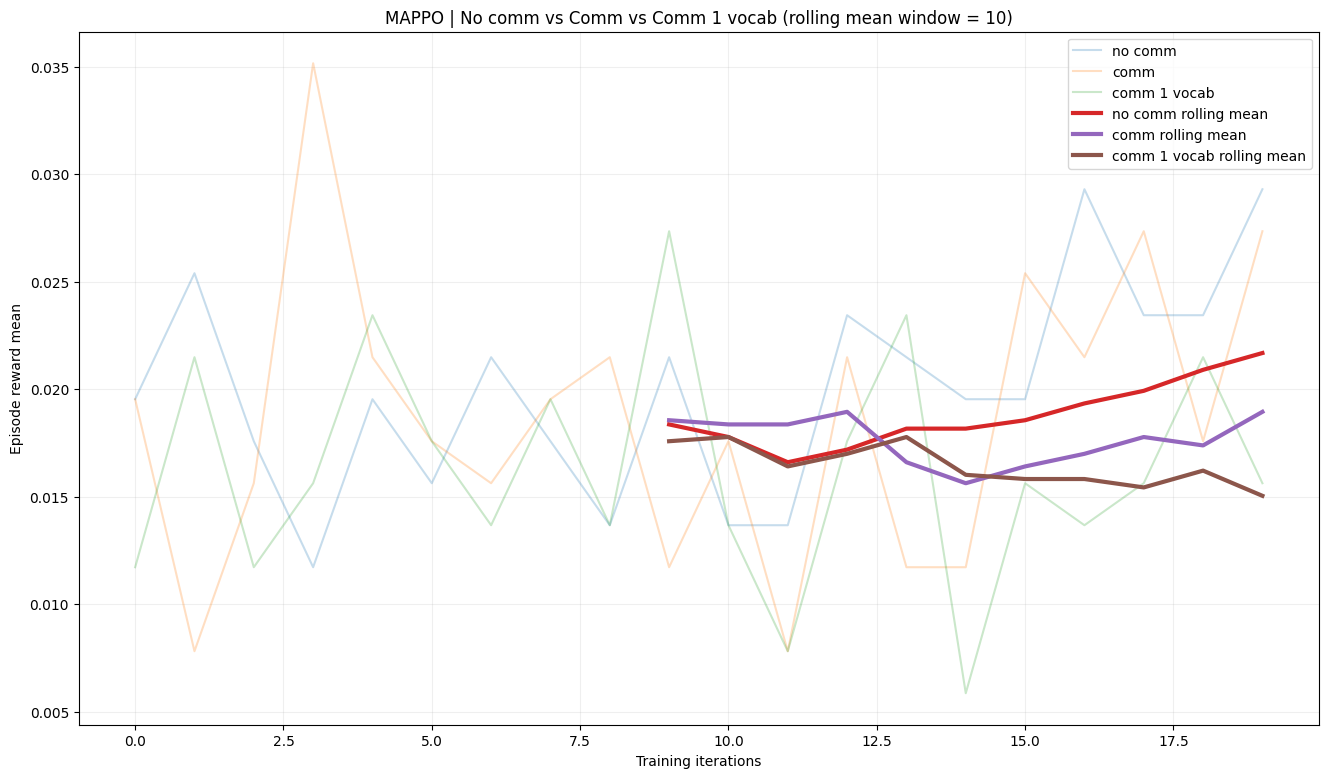

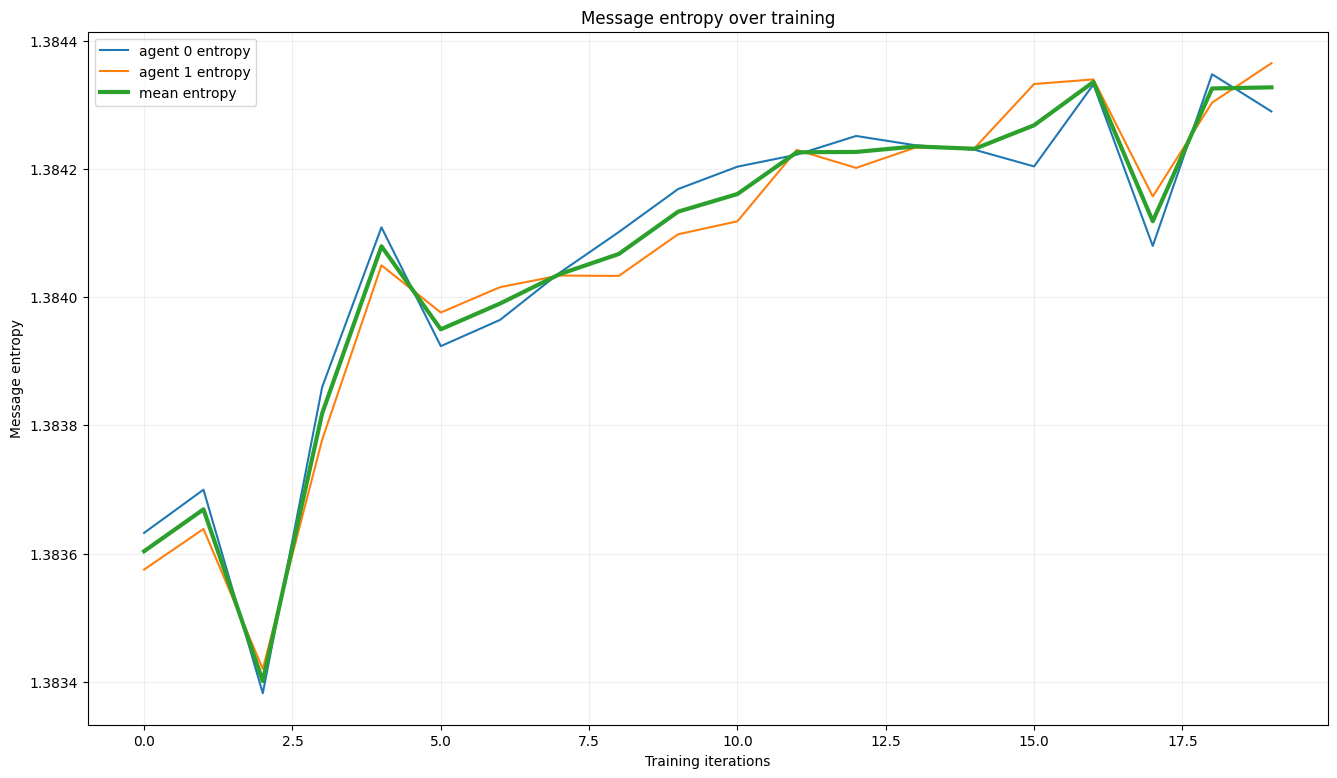

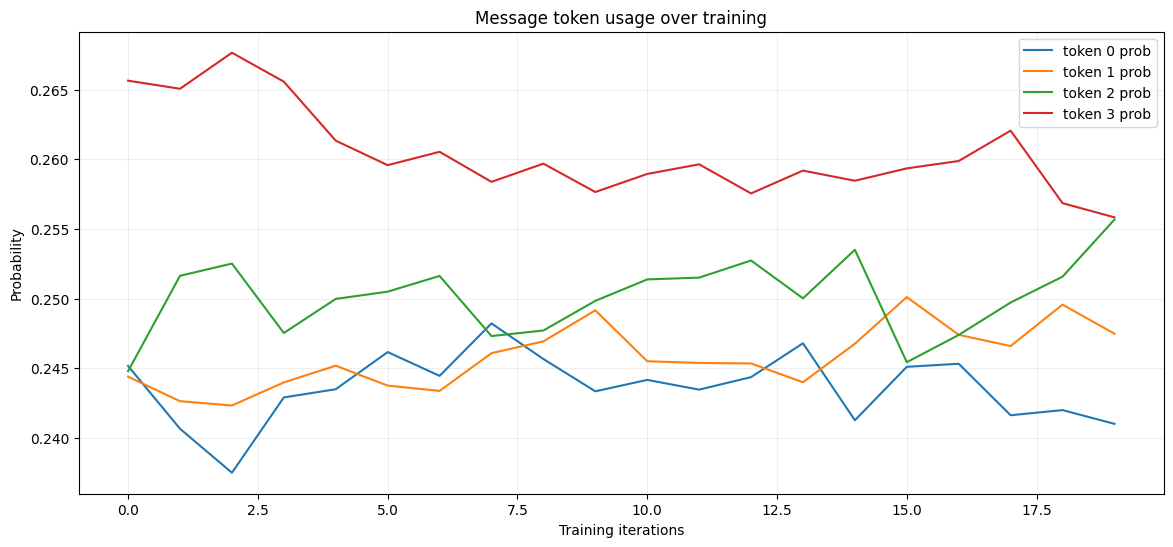

In [29]:
w = 10

x_nc = np.array(nocomm_rewards)
x_c  = np.array(comm_rewards)
x_c1 = np.array(comm_rewards_1vocab)

rm_nc = rolling_mean(x_nc, w)
rm_c  = rolling_mean(x_c,  w)
rm_c1 = rolling_mean(x_c1, w)

plt.figure(figsize=(16, 9))

plt.plot(x_nc, alpha=0.25, label="no comm")
plt.plot(x_c,  alpha=0.25, label="comm")
plt.plot(x_c1, alpha=0.25, label="comm 1 vocab")

plt.plot(rm_nc, linewidth=3, label=f"no comm rolling mean")
plt.plot(rm_c,  linewidth=3, label=f"comm rolling mean")
plt.plot(rm_c1, linewidth=3, label=f"comm 1 vocab rolling mean")

plt.xlabel("Training iterations")
plt.ylabel("Episode reward mean")
plt.title("MAPPO | No comm vs Comm vs Comm 1 vocab (rolling mean window = 10)")
plt.legend()
plt.grid(True, alpha=0.2)
plt.savefig("mappo.png", dpi=300)
plt.show()

plot_message_entropy(comm_entropy, "mappo_entropy.png")

plot_message_counts(comm_counts, "mappo_counts.png", vocab_size=VOCAB_SIZE)

In [30]:
set_seeds(0)
env.set_seed(1234)

def build_critic(env, n_agents, device="cpu", mappo=False, share_params=True):
    critic_net = MultiAgentMLP(
        n_agent_inputs=env.observation_spec["observation"].shape[-1],
        n_agent_outputs=1,
        n_agents=n_agents,
        centralised=mappo,
        share_params=share_params,
        device=device,
        depth=2,
        num_cells=256,
        activation_class=torch.nn.Tanh
    )

    return TensorDictModule(
        critic_net,
        in_keys=["observation"],
        out_keys=["state_value"]
    )


set_seeds(0)
env.set_seed(1234)
vocab_size = 4

nocomm_critic = build_critic(env, n_agents=n_agents, device=device, mappo=False, share_params=True)
nocomm_actor = build_nocomm_actor(env, n_agents=n_agents, device=device, share_params=True)

nocomm_rewards, _, _ = train_run(
    env,
    nocomm_actor,
    nocomm_actor,
    nocomm_critic,
    frames_per_batch=frames_per_batch,
    total_frames=total_frames,
    n_iters=n_iters,
    minibatch_size=minibatch_size,
    num_epochs=num_epochs,
    lr=lr,
    vocab_size=vocab_size,
    max_grad_norm=max_grad_norm,
    clip_epsilon=clip_epsilon,
    gamma=gamma,
    lmbda=lmbda,
    entropy_eps=entropy_eps,
    device=device,
    log_messages=False
)



set_seeds(0)
env.set_seed(1234)
vocab_size = VOCAB_SIZE

comm_critic = build_critic(env, n_agents=n_agents, device=device, mappo=False, share_params=True)
comm_collector_policy, comm_ppo_actor = build_comm_policy(env, n_agents=n_agents, vocab_size=VOCAB_SIZE, device=device)

comm_rewards, comm_entropy, comm_counts = train_run(
    env,
    comm_collector_policy,
    comm_ppo_actor,
    comm_critic,
    frames_per_batch=frames_per_batch,
    total_frames=total_frames,
    n_iters=n_iters,
    minibatch_size=minibatch_size,
    num_epochs=num_epochs,
    lr=lr,
    vocab_size=vocab_size,
    max_grad_norm=max_grad_norm,
    clip_epsilon=clip_epsilon,
    gamma=gamma,
    lmbda=lmbda,
    entropy_eps=entropy_eps,
    device=device,
    log_messages=True
)

set_seeds(0)
vocab_size = 1

comm_critic_1vocab = build_critic(env, n_agents=n_agents, device=device, mappo=False, share_params=True)
comm_collector_policy_1vocab, comm_ppo_actor_1vocab = build_comm_policy(env, n_agents=n_agents, vocab_size=vocab_size, device=device)

comm_rewards_1vocab, _, _ = train_run(
    env,
    comm_collector_policy_1vocab,
    comm_ppo_actor_1vocab,
    comm_critic_1vocab,
    frames_per_batch=frames_per_batch,
    total_frames=total_frames,
    n_iters=n_iters,
    minibatch_size=minibatch_size,
    num_epochs=num_epochs,
    lr=lr,
    vocab_size=vocab_size,
    max_grad_norm=max_grad_norm,
    clip_epsilon=clip_epsilon,
    gamma=gamma,
    lmbda=lmbda,
    entropy_eps=entropy_eps,
    device=device,
    log_messages=False
)

episode_reward_mean = 0.017578125: 100%|██████████| 20/20 [07:20<00:00, 22.04s/it]


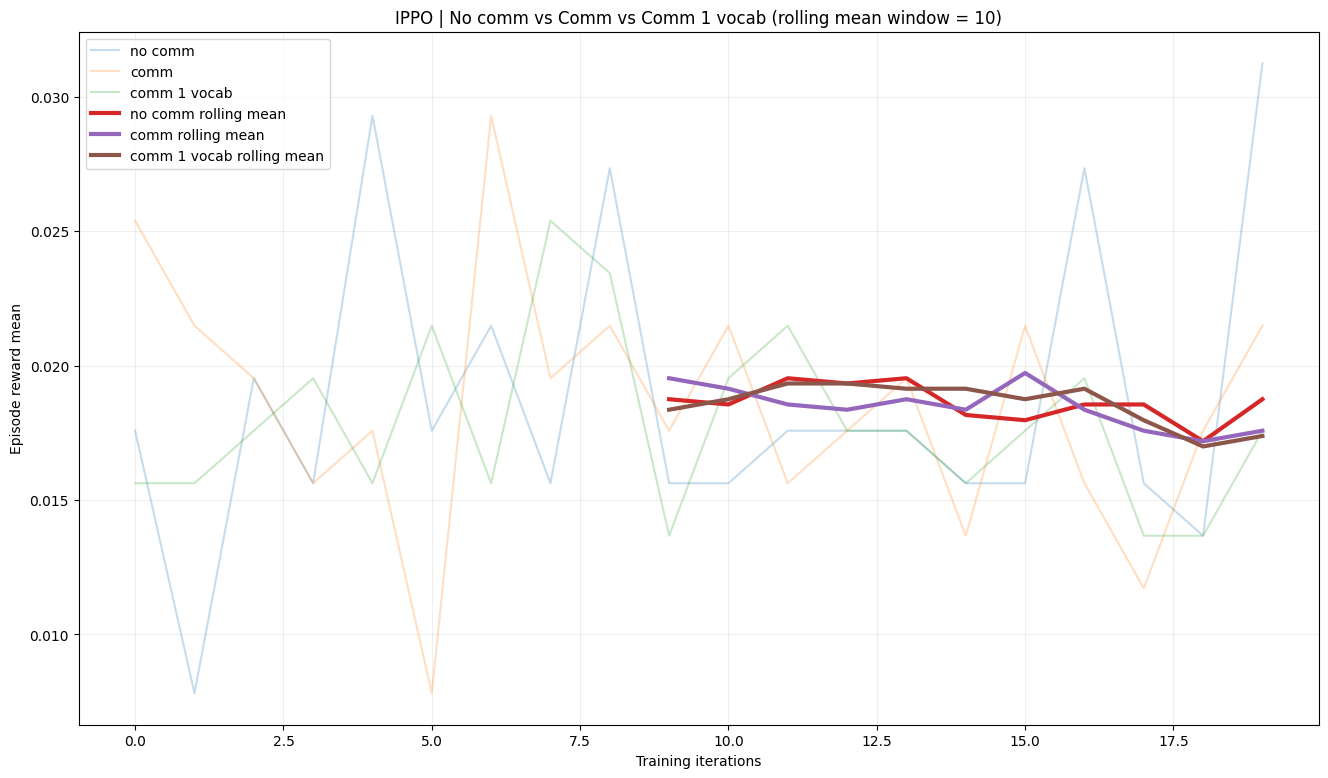

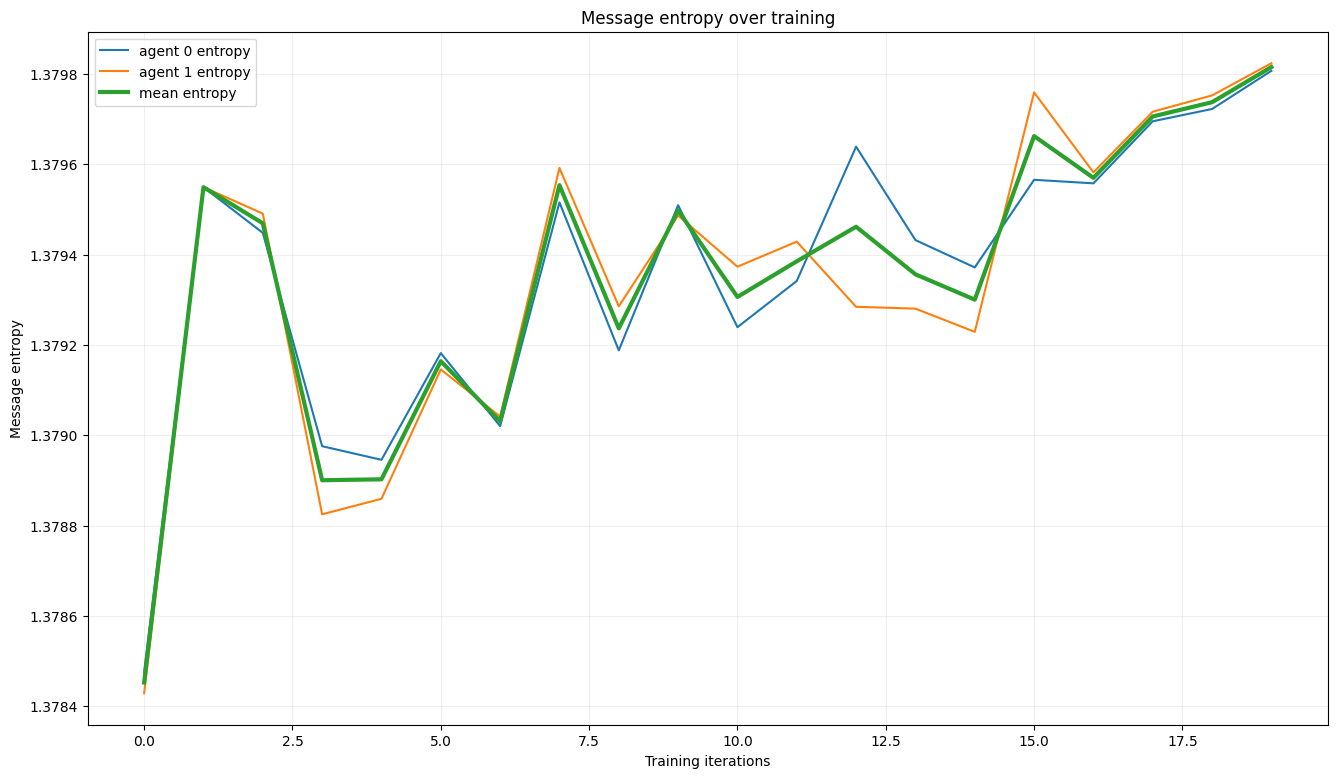

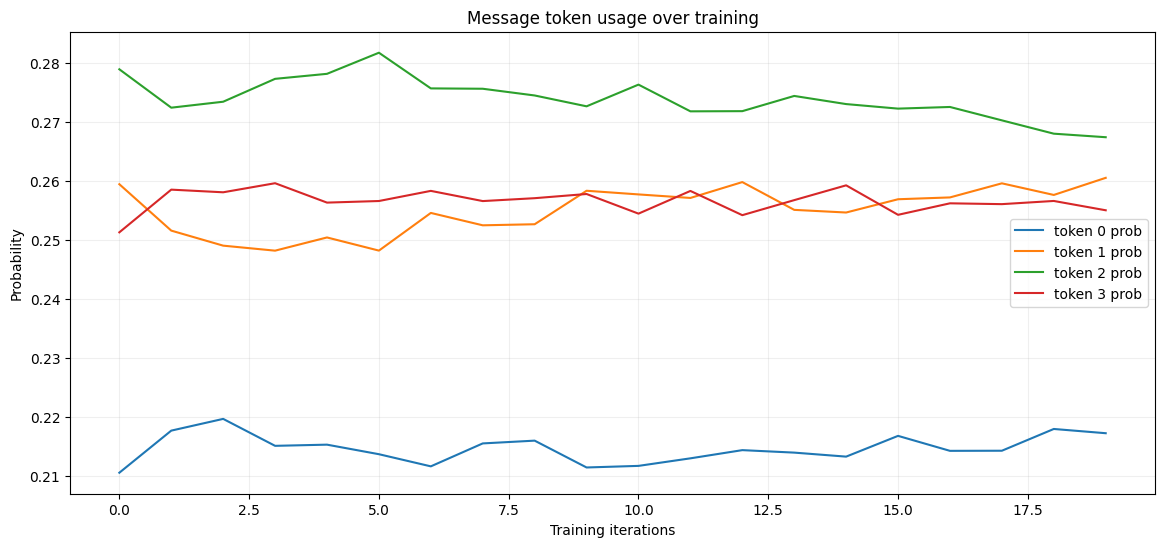

In [31]:
w = 10

x_nc = np.array(nocomm_rewards)
x_c  = np.array(comm_rewards)
x_c1 = np.array(comm_rewards_1vocab)

rm_nc = rolling_mean(x_nc, w)
rm_c  = rolling_mean(x_c,  w)
rm_c1 = rolling_mean(x_c1, w)

plt.figure(figsize=(16, 9))

plt.plot(x_nc, alpha=0.25, label="no comm")
plt.plot(x_c,  alpha=0.25, label="comm")
plt.plot(x_c1, alpha=0.25, label="comm 1 vocab")

plt.plot(rm_nc, linewidth=3, label=f"no comm rolling mean")
plt.plot(rm_c,  linewidth=3, label=f"comm rolling mean")
plt.plot(rm_c1, linewidth=3, label=f"comm 1 vocab rolling mean")

plt.xlabel("Training iterations")
plt.ylabel("Episode reward mean")
plt.title("IPPO | No comm vs Comm vs Comm 1 vocab (rolling mean window = 10)")
plt.legend()
plt.grid(True, alpha=0.2)
plt.savefig("ippo.png", dpi=300)
plt.show()

plot_message_entropy(comm_entropy, "ippo_entropy.png")

plot_message_counts(comm_counts, "ippo_counts.png", vocab_size=VOCAB_SIZE)

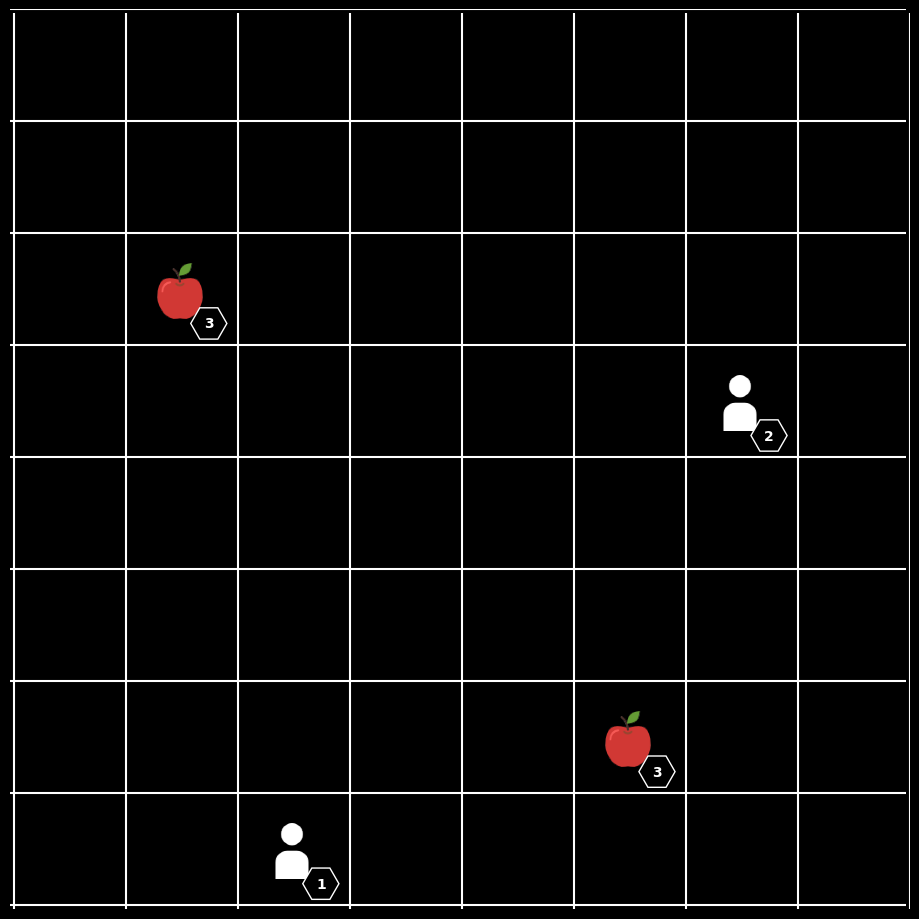

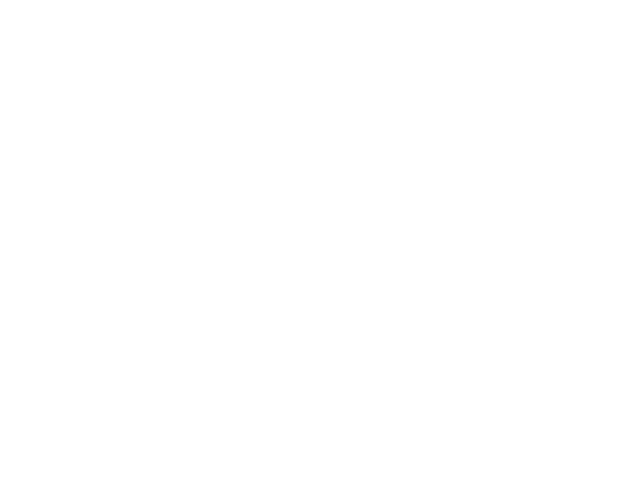

In [32]:

tds = env.rollout(
    max_steps=100,
    policy=comm_collector_policy,
    callback=jumanji_env_render_callback
)

jumanji_env_render_callback(env, tds[-1]["next"])
cv2.destroyAllWindows()
